# Baseline Comparison

Runs all baseline models on the same evaluation sets and produces a unified comparison table.

| Model | Type | Notes |
|---|---|---|
| Presidio | Rule-based | Microsoft open-source PHI anonymizer |
| GLiNER | Zero-shot NER | `urchade/gliner_mediumv2.1` |
| RoBERTa-i2b2 | Fine-tuned NER | `obi/deid_roberta_i2b2` |
| scispaCy | Medical NER | `en_core_web_lg` (not de-id specific) |
| Stanford-deid | Fine-tuned NER | `StanfordAIMI/stanford-deidentifier-base` |
| BERT-i2b2 | Fine-tuned NER | `obi/deid_bert_i2b2` (ClinicalBERT sibling of RoBERTa-i2b2) |
| OpenMed-PII | Fine-tuned NER | `OpenMed/OpenMed-PII-SuperClinical-Large-434M-v1` (DeBERTa-v3, 54 PII types) |
| OPF | Span-decode NER | `openai/privacy-filter` (1.5B / 50M active, 8 PII categories; install from repo) |
| EdgeDeID-SFT | Ours | Qwen3-0.6B SFT |
| EdgeDeID-GRPO | Ours | Qwen3-0.6B SFT + GRPO |

## 0 — Setup

In [1]:
import sys
sys.path.insert(0, "../..")

import pandas as pd
from tqdm import tqdm

from pipeline.data.preprocessing import preprocess_text
from pipeline.data.xml_utils import convert_to_xml
from pipeline.eval import compute_metrics, print_report, to_dataframe

# ── dataset selection ────────────────────────────────────────────────────────
# "synth" = held-out synthetic test set (LLM Eval.xlsx)
# "ext"   = external English benchmark
# "test"  = test.csv from HF dataset (data/test.csv)
DATASET = "test"   # change to "synth" or "ext" as needed

if DATASET == "synth":
    raw_df = pd.read_excel("../synth_eval/LLM Eval.xlsx")
    raw_df.rename(columns={"Revision": "default_response_1"}, inplace=True)
    raw_df = preprocess_text(raw_df, input_col="default_response_0", output_col="default_response_1")
    raw_df["GT-XML"] = raw_df["default_response_1"].apply(convert_to_xml)
    NOTE_COL = "default_response_0"
elif DATASET == "ext":
    raw_df = pd.read_csv("../ext_eval/en_data.csv")
    raw_df = preprocess_text(raw_df, input_col="Report", output_col="DeID")
    raw_df["GT-XML"] = raw_df["DeID"].apply(convert_to_xml)
    NOTE_COL = "Report"
elif DATASET == "test":
    raw_df = pd.read_csv("../../data/test.csv")
    print(raw_df.shape)
    raw_df = preprocess_text(raw_df, input_col="original", output_col="anonymized")
    raw_df["GT-XML"] = raw_df["anonymized"].apply(convert_to_xml)
    NOTE_COL = "original"
    print(raw_df.shape)
else:
    raise ValueError(f"Unknown DATASET: {DATASET!r}. Choose 'synth', 'ext', or 'test'.")

for tag in ["<anonymized_report>", "</anonymized_report>", "<anonymized_report/>",
            "<raw_report>", "</raw_report>", "<raw_report/>"]:
    raw_df[NOTE_COL] = raw_df[NOTE_COL].str.replace(tag, "", regex=False).str.strip()

notes     = raw_df[NOTE_COL].tolist()
gt_xmls   = raw_df["GT-XML"].tolist()
print(f"{len(notes)} evaluation samples | dataset={DATASET}")

(404, 3)
Starting text processing pipeline...
Fixing spaces in closing tags...
Fixing spaces in tags...
Processing phone numbers...
Processing dates...
Processing ages...
Correcting gender terms...
Processing name tags...
Simplifying name tags...
Reformatting ID tags...
Processing remaining dates...
Removing markdown tags...

Processing Summary:
  Entity       Detected  Reformatted
  ----------  ---------  -----------
  name              700            -
  age               332            -
  date              589            -
  place             256            -
  address           214            -
  phone             221            -
  email             215            -
  id                232            -
  url               293            -
  device            228            -

Text processing pipeline completed!
(377, 4)
377 evaluation samples | dataset=test


In [10]:
raw_df.head()

,anonymized,original,examples,GT-XML
0,"<phi_entities>\n<names>\n<name id=""1"" type=""pa...","(2024), Liam Novak (URL: https://myhealthonlin...",NONE,"<phi_entities>\n<names>\n<name id=""1"" type=""pa..."
1,"<phi_entities>\n<names>\n<name id=""1"" type=""pa...","On 2023, Liam Novak, a 68y male patient with a...",NONE,"<phi_entities>\n<names>\n<name id=""1"" type=""pa..."
2,"<phi_entities>\n<names>\n<name id=""1"" type=""pr...","Dear Dr. Larsson, I hope this email finds you ...",NONE,"<phi_entities>\n<names>\n<name id=""1"" type=""pr..."
3,"<phi_entities>\n<names>\n<name id=""1"" type=""pr...","Mr. Pt, email: d.kim1980@email.com, visited Me...",NONE,"<phi_entities>\n<names>\n<name id=""1"" type=""pr..."
4,"<phi_entities>\n<names>\n<name id=""1"" type=""pa...","Mr. David Okafor, a 58year-old man residing at...",NONE,"<phi_entities>\n<names>\n<name id=""1"" type=""pa..."


In [2]:
from pipeline.data.preprocessing import preprocess_text, inspect_changes
raw_df = pd.read_csv("../../data/test.csv")
before_col = raw_df['anonymized'].copy()          # snapshot before
df = preprocess_text(raw_df, input_col='original', output_col='anonymized')

# All changed rows (default 5 samples)
inspect_changes(before_col, df['anonymized'])

# Filter to a specific entity type
inspect_changes(before_col, df['anonymized'], entity='date', n=3)
inspect_changes(before_col, df['anonymized'], entity='phone')

# More/less context lines around each change
inspect_changes(before_col, df['anonymized'], entity='name', context=1)


Starting text processing pipeline...
Fixing spaces in closing tags...
Fixing spaces in tags...
Processing phone numbers...
Processing dates...
Processing ages...
Correcting gender terms...
Processing name tags...
Simplifying name tags...
Reformatting ID tags...
Processing remaining dates...
Removing markdown tags...

Processing Summary:
  Entity       Detected  Reformatted
  ----------  ---------  -----------
  name              700            -
  age               332            -
  date              589            -
  place             256            -
  address           214            -
  phone             221            -
  email             215            -
  id                232            -
  url               293            -
  device            228            -

Text processing pipeline completed!
376 row(s) changed.

────────────────────────────────────────────────────────────────
  [1/5]  row index 0
@@ -8,7 +8,5 @@
 </name>

 <name id="2" type="provider">

-<variations>



In [3]:
raw_df = pd.read_csv("../../data/test.csv")
raw_df

,anonymized,original,examples
0,"<phi_entities>\n<names>\n<name id=""1"" type=""pa...","(2024), Liam Novak (URL: https://myhealthonlin...",NONE
1,"<phi_entities>\n<names>\n<name id=""1"" type=""pa...","On 2023, Liam Novak, a 68y male patient with a...",NONE
2,"<phi_entities>\n<names>\n<name id=""1"" type=""pr...","Dear Dr. Larsson, I hope this email finds you ...",NONE
3,"<phi_entities>\n<names>\n<name id=""1"" type=""pr...","Mr. Pt, email: d.kim1980@email.com, visited Me...",NONE
4,"<phi_entities>\n<names>\n<name id=""1"" type=""pa...","Mr. David Okafor, a 58year-old man residing at...",NONE
...,...,...,...
399,"<phi_entities>\n<names>\n<name id=""1"" type=""pr...","08-30-18, Pt, 68y man, presented to Cleveland ...",NONE
400,"<phi_entities>\n<names>\n<name id=""1"" type=""pa...","David Kim, a 28 years old male, visited the cl...",NONE
401,"<phi_entities>\n<names>\n<name id=""1"" type=""pa...","Mr. David Okafor, 28 years old, presented with...",NONE
402,"<phi_entities>\n<names>\n<name id=""1"" type=""pa...","David cKim, a 28 yo male, visited Mercy Hospit...",NONE


## 1 — Load Baseline Models

Comment out any baselines whose dependencies are not installed.

In [ ]:
import datasets
from pathlib import Path

from baselines import (
    PresidioBaseline, GLiNERBaseline, RobertaDeidBaseline, ScispaCyBaseline,
    StanfordDeidBaseline, BertDeidBaseline, OpenMedPIIBaseline, QwenDeidBaseline,
    OPFBaseline,
)

# our SFT checkpoint: prefer a local copy, else pull from the Hub
_sft_local = Path("../../models/Qwen3-0.6B-Base_SFT")
_sft_src = str(_sft_local) if _sft_local.exists() else "EdgeDeID/Qwen3-0.6B-Base_SFT"

models = [
    PresidioBaseline(score_threshold=0.5),
    GLiNERBaseline(model_name="urchade/gliner_mediumv2.1", threshold=0.5),
    RobertaDeidBaseline(model_name="obi/deid_roberta_i2b2"),
    ScispaCyBaseline(model_name="en_core_web_lg"),
    #StanfordDeidBaseline(),
    BertDeidBaseline(model_name="obi/deid_bert_i2b2"),
    OpenMedPIIBaseline(model_name="OpenMed/OpenMed-PII-SuperClinical-Large-434M-v1"),
    # OpenAI Privacy Filter (1.5B). Not on PyPI — install from the cloned repo:
    #   git clone https://github.com/openai/privacy-filter && pip install -e privacy-filter
    # Weights auto-download to ~/.opf/privacy_filter on first use. Uncomment once installed.
    #OPFBaseline(),
    # Qwen3-0.6B causal LMs — emit <phi_entities> XML directly. Heavy: each loads
    # ~1.2 GB and runs ~5-10 s/note, so the loop in Section 2 will take a while.
    QwenDeidBaseline("Qwen/Qwen3-0.6B-Base", name="Qwen3-0.6B-Base (zero-shot)"),
    QwenDeidBaseline(_sft_src, name="EdgeDeID-Qwen3-0.6B"),
]
print("Loaded:", [m.name for m in models])

In [3]:
import os

# Set proxy for standard HTTP/HTTPS traffic
os.environ["http_proxy"] = "http://127.0.0.1:10809"
os.environ["https_proxy"] = "http://127.0.0.1:10809"

# Set fallback proxy for all other traffic (requires httpx[socks])
os.environ["all_proxy"] = "socks5://127.0.0.1:10808"

print("Proxy environment variables set.")

Proxy environment variables set.


## 2 — Run Baselines

In [ ]:
all_results = {}   # model_name -> EvalResult

for model in models:
    print(f"\nRunning {model.name} ...")
    predictions = [
        model.predict_xml(note)
        for note in tqdm(notes, desc=model.name)
    ]
    result = compute_metrics(
        predictions, gt_xmls, source_notes=notes,
        supported_entities=model.supported_entities,
    )
    all_results[model.name] = result
    print_report(result, title=model.name)

## 3 — GRPO Model (placeholder)

Our SFT and base Qwen3-0.6B models now run in the Section 2 loop (added to `models`).
Only the GRPO checkpoint remains to be wired in here once it's trained.

In [ ]:
# GRPO model — wire in once the checkpoint is trained. Same QwenDeidBaseline
# wrapper as the SFT/base models above; just point it at the GRPO checkpoint and
# append to `all_results` so it flows into the comparison table / plots below.
#
# grpo = QwenDeidBaseline("EdgeDeID/Qwen3-0.6B-GRPO", name="EdgeDeID-GRPO")
# print(f"\nRunning {grpo.name} ...")
# predictions = [grpo.predict_xml(note) for note in tqdm(notes, desc=grpo.name)]
# all_results[grpo.name] = compute_metrics(
#     predictions, gt_xmls, source_notes=notes,
#     supported_entities=grpo.supported_entities,
# )
# print_report(all_results[grpo.name], title=grpo.name)

## 4 — Comparison Table

In [ ]:
rows = []
for model_name, r in all_results.items():
    rows.append({
        "Model":              model_name,
        "Micro-P":            round(r.micro_precision, 4),
        "Micro-R":            round(r.micro_recall, 4),
        "Micro-F1":           round(r.micro_f1, 4),
        "F-β(2)":             round(r.f_beta, 4),
        "Macro-F1":           round(r.macro_f1, 4),
        "Zero-leak":          round(r.zero_leak_rate, 4),
        "XML Parse Rate":     round(r.xml_parse_rate, 4),
        "Hallucination Rate": round(r.hallucination_rate, 4),
        "Token Reduction":    round(r.token_reduction_rate, 4) if r.token_reduction_rate == r.token_reduction_rate else None,
    })

comparison_df = pd.DataFrame(rows).set_index("Model")
comparison_df

,Micro-P,Micro-R,Micro-F1,F-β(2),Macro-F1,Zero-leak,XML Parse Rate,Hallucination Rate,Token Reduction
Model,,,,,,,,,
Presidio,0.5344,0.6453,0.5846,0.6196,0.6908,0.0451,1.0,0.4656,0.1413
GLiNER,0.7731,0.6734,0.7198,0.6913,0.7018,0.2042,1.0,0.2269,0.1612
RoBERTa-i2b2,0.4978,0.7785,0.6073,0.6996,0.6507,0.1883,1.0,0.5022,0.1459
scispaCy,0.3860,0.4525,0.4166,0.4374,0.1482,0.0212,1.0,0.6140,0.1572


In [ ]:
import os
os.makedirs("results", exist_ok=True)

out_path = f"results/baseline_comparison_{DATASET}.csv"
comparison_df.to_csv(out_path)
print(f"Saved {out_path}")

Saved results/baseline_comparison_test.csv


## 5 — Per-Entity Breakdown

In [ ]:
all_entity_tags = sorted(
    set(tag for r in all_results.values() for tag in r.per_entity)
)
per_entity_rows = []
for entity in all_entity_tags:
    row = {"Entity": entity}
    for model_name, r in all_results.items():
        m = r.per_entity.get(entity)
        row[model_name] = round(m.f1, 4) if m else None
    per_entity_rows.append(row)

per_entity_df = pd.DataFrame(per_entity_rows).set_index("Entity")

out_path = f"results/baseline_per_entity_{DATASET}.csv"
per_entity_df.to_csv(out_path)
print(f"Saved {out_path}")
per_entity_df

Saved results/baseline_per_entity_test.csv


,Presidio,GLiNER,RoBERTa-i2b2,scispaCy
Entity,,,,
address,0.5796,0.7148,0.4046,0.0000
age,NaN,0.7668,0.9836,0.0000
date,0.4927,0.8341,0.6867,0.4496
device,NaN,0.7595,NaN,0.0000
email,0.9953,0.5528,0.6909,0.0000
id,NaN,0.7633,0.6364,0.0000
name,0.7884,0.6762,0.6829,0.7741
phone,0.6957,0.8994,0.6506,0.0000
place,NaN,0.7198,0.4698,0.2584


## 6 — Plots

Visual summaries of the results above (also saved as PNGs in `results/`):

1. **Per-entity F1 heatmap** — capability profile per model; grey = entity the model can't emit (`supported_entities`).
2. **Per-entity recall heatmap** — the safety view; red cells are PHI types the model lets leak.
3. **Precision–Recall scatter** — one point per model with F1 iso-curves, showing the precision/recall trade-off.
4. **Headline metrics bars** — micro-F1, recall, zero-leak, macro-F1 side by side.

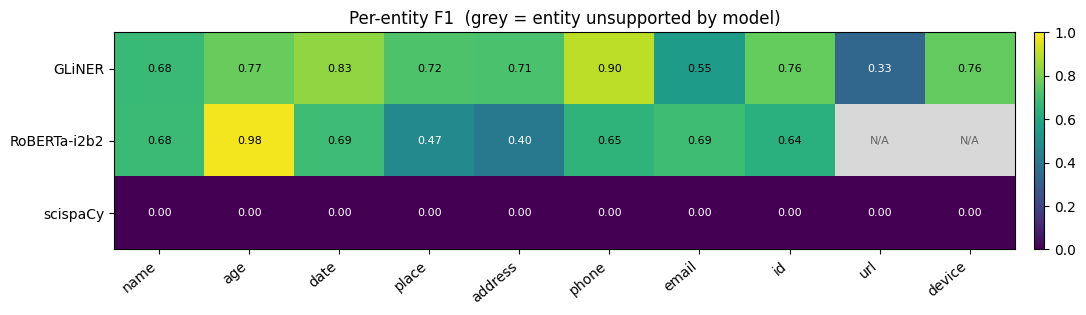

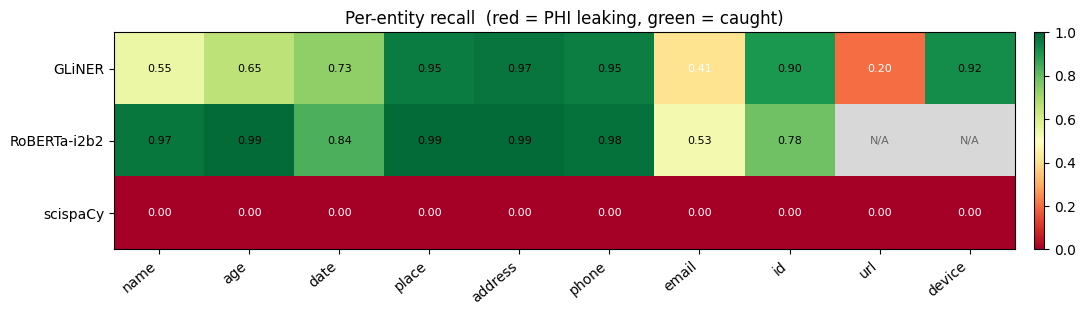

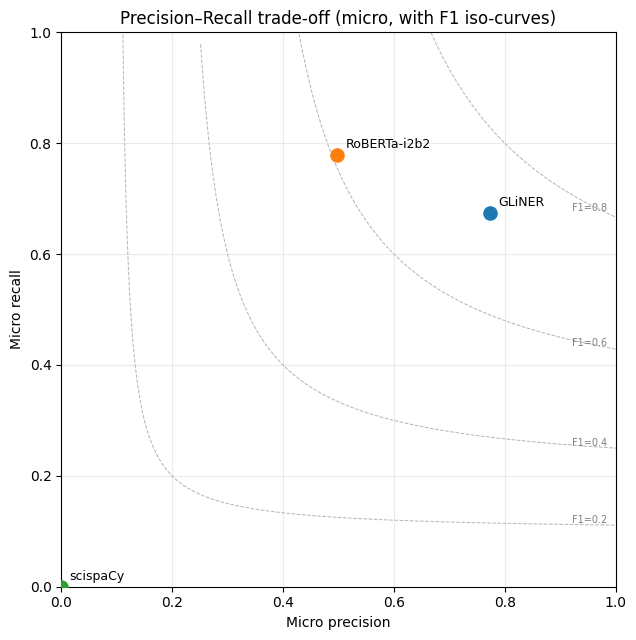

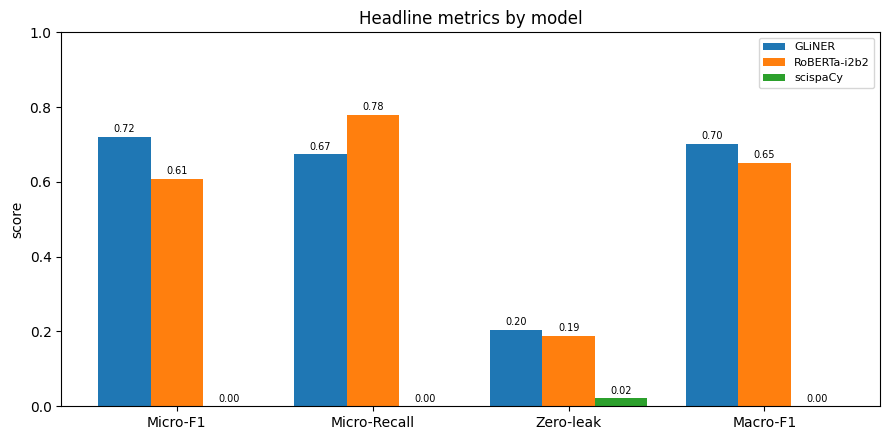

Saved 4 plots to results/


In [8]:
import numpy as np
import matplotlib.pyplot as plt

ALL_TAGS = ["name", "age", "date", "place", "address",
            "phone", "email", "id", "url", "device"]
model_names = list(all_results.keys())


def _entity_matrix(attr):
    """models × entities matrix of a TagMetrics attr (NaN = unsupported / N/A)."""
    M = np.full((len(model_names), len(ALL_TAGS)), np.nan)
    for i, mn in enumerate(model_names):
        pe = all_results[mn].per_entity
        for j, t in enumerate(ALL_TAGS):
            m = pe.get(t)
            if m is not None:
                M[i, j] = getattr(m, attr)
    return M


def _heatmap(M, title, fname, cmap_name):
    cmap = plt.get_cmap(cmap_name).copy()
    cmap.set_bad("0.85")  # grey cells = entity the model can't emit (N/A)
    fig, ax = plt.subplots(figsize=(11, 1.6 + 0.55 * len(model_names)))
    im = ax.imshow(M, cmap=cmap, vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(ALL_TAGS)))
    ax.set_xticklabels(ALL_TAGS, rotation=40, ha="right")
    ax.set_yticks(range(len(model_names)))
    ax.set_yticklabels(model_names)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M[i, j]
            ax.text(j, i, "N/A" if np.isnan(v) else f"{v:.2f}",
                    ha="center", va="center", fontsize=8,
                    color="0.4" if np.isnan(v) else ("white" if v < 0.5 else "black"))
    ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
    plt.tight_layout()
    plt.savefig(f"results/{fname}", dpi=150, bbox_inches="tight")
    plt.show()


# 1) Per-entity F1 — capability profile (grey = unsupported by that model)
_heatmap(_entity_matrix("f1"),
         "Per-entity F1  (grey = entity unsupported by model)",
         f"plot_f1_heatmap_{DATASET}.png", "viridis")

# 2) Per-entity recall — the safety / leak view (red = PHI being missed)
_heatmap(_entity_matrix("recall"),
         "Per-entity recall  (red = PHI leaking, green = caught)",
         f"plot_recall_heatmap_{DATASET}.png", "RdYlGn")

# 3) Precision–Recall trade-off, one point per model, with F1 iso-curves
fig, ax = plt.subplots(figsize=(6.5, 6.5))
pp = np.linspace(0.001, 1, 400)
for f1 in (0.2, 0.4, 0.6, 0.8):
    rr = np.where(2 * pp - f1 > 0, f1 * pp / (2 * pp - f1), np.nan)
    rr[(rr <= 0) | (rr > 1)] = np.nan
    ax.plot(pp, rr, "--", color="0.7", lw=0.7)
    ax.text(0.985, f1 * 0.985 / (2 * 0.985 - f1), f"F1={f1}",
            color="0.5", fontsize=7, va="bottom", ha="right")
for mn in model_names:
    r = all_results[mn]
    ax.scatter(r.micro_precision, r.micro_recall, s=90, zorder=3)
    ax.annotate(mn, (r.micro_precision, r.micro_recall),
                textcoords="offset points", xytext=(6, 5), fontsize=9)
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
ax.set_xlabel("Micro precision"); ax.set_ylabel("Micro recall")
ax.set_title("Precision–Recall trade-off (micro, with F1 iso-curves)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(f"results/plot_pr_scatter_{DATASET}.png", dpi=150, bbox_inches="tight")
plt.show()

# 4) Headline metrics — grouped bars
headline = [("Micro-F1", "micro_f1"), ("Micro-Recall", "micro_recall"),
            ("Zero-leak", "zero_leak_rate"), ("Macro-F1", "macro_f1")]
x = np.arange(len(headline)); w = 0.8 / max(len(model_names), 1)
fig, ax = plt.subplots(figsize=(9, 4.5))
for i, mn in enumerate(model_names):
    vals = [getattr(all_results[mn], a) for _, a in headline]
    bars = ax.bar(x + i * w, vals, w, label=mn)
    ax.bar_label(bars, fmt="%.2f", fontsize=7, padding=2)
ax.set_xticks(x + w * (len(model_names) - 1) / 2)
ax.set_xticklabels([n for n, _ in headline])
ax.set_ylim(0, 1); ax.set_ylabel("score")
ax.set_title("Headline metrics by model"); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"results/plot_headline_bars_{DATASET}.png", dpi=150, bbox_inches="tight")
plt.show()

print("Saved 4 plots to results/")